# Assignment 9: Image Classification using Pre-trained Vision Transformer (ViT) vs. Convolutional Neural Network (CNN)

**Course:** Deep Learning Laboratory  
**Frameworks:** PyTorch, Torchvision, Scikit-Learn, NumPy, Matplotlib, Seaborn  
**Dataset:** CIFAR-10 (10 Classes)  
**Models:** Vision Transformer (`ViT-B/16`) vs. Deep CNN (`ResNet-18`)

---

## 🎯 Executive Summary & Theoretical Background

For nearly a decade, **Convolutional Neural Networks (CNNs)** have stood as the unchallenged paradigm for computer vision tasks. CNN architectures such as AlexNet, VGG, and ResNet were designed around hardcoded **spatial inductive biases**:
1. **Locality:** Nearby pixels share meaningful contextual relationships (captured via localized $3 \times 3$ or $5 \times 5$ convolution kernels).
2. **Translation Equivariance:** If an object shifts spatially within an image, its feature representation shifts identically ($f(g(x)) = g(f(x))$).

In 2020, Dosovitskiy et al. (*"An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale"*, ICLR 2021) introduced the **Vision Transformer (ViT)**, demonstrating that standard Transformer architectures originally developed for Natural Language Processing can be directly adapted to image classification with minimal modifications.

### How Vision Transformers Work:
1. **Patch Extraction & Flattening:** An input image $X \in \mathbb{R}^{H \times W \times C}$ is partitioned into a sequence of $N = \frac{HW}{P^2}$ non-overlapping patches of size $P \times P$. For a standard $224 \times 224$ image with patch size $P=16$, this yields $14 \times 14 = 196$ image patches.
2. **Linear Projection (Patch Embedding):** Each flattened patch vector ($x_p \in \mathbb{R}^{P^2 C} = 768$) is linearly projected into a continuous latent embedding space of dimension $D = 768$ using a learnable matrix $E$:
   $$\mathbf{z}_0 = [\mathbf{x}_{\text{class}}; \mathbf{x}_p^1 \mathbf{E}; \mathbf{x}_p^2 \mathbf{E}; \dots; \mathbf{x}_p^N \mathbf{E}] + \mathbf{E}_{\text{pos}}$$
3. **Class Token (`[CLS]`):** A learnable class token embedding $\mathbf{x}_{\text{class}} \in \mathbb{R}^D$ is prepended to the patch sequence. Its state at the final Transformer layer serves as the aggregate image representation.
4. **Learnable Position Embeddings:** Because Transformers are permutation-invariant, 1D learnable position embeddings $\mathbf{E}_{\text{pos}} \in \mathbb{R}^{(N+1) \times D}$ are added to retain spatial geometry.
5. **Multi-Head Self-Attention (MHSA):** In contrast to local convolutions, every patch token directly attends to every other patch token globally across all layers:
   $$\text{Attention}(\mathbf{Q}, \mathbf{K}, \mathbf{V}) = \text{softmax}\left(\frac{\mathbf{Q} \mathbf{K}^T}{\sqrt{d_k}}\right) \mathbf{V}$$

### 🔬 CNN vs. ViT: Architectural Comparison

| Dimension | Convolutional Neural Network (CNN) | Vision Transformer (ViT) |
|---|---|---|
| **Fundamental Operation** | Local Convolution ($3 \times 3$ sliding filters) | Global Multi-Head Self-Attention (MHSA) |
| **Inductive Bias** | Strong (Locality + Translation Equivariance) | Weak (Must learn spatial topology from data) |
| **Receptive Field** | Grows hierarchically with network depth | Global across all tokens at Layer 1 |
| **Data Requirement** | High sample efficiency on small/medium datasets | Requires large-scale pre-training (ImageNet-21k/JFT) |
| **Computational Scaling** | Linear with spatial dimensions $\mathcal{O}(H \cdot W)$ | Quadratic with patch count $\mathcal{O}(N^2)$ |

---

## 📋 Experiment Workflow
1. **Environment & Device Configuration:** Setup PyTorch and hardware detection.
2. **Data Pipeline:** Load CIFAR-10 with standardized $224 \times 224$ ImageNet normalization.
3. **Dataset Visualization:** Display sample images across the 10 classes.
4. **Visualizing the ViT Patching Process:** Deconstruct a sample image into its 196 constituent $16 \times 16$ tokens.
5. **Model Instantiation:** Load pre-trained **ResNet-18** and **ViT-B/16**, freeze backbones, and attach classification heads.
6. **Architectural & Parameter Profiling:** Contrast parameter counts, trainable weights, and model footprints.
7. **Model Training:** Train both models under identical optimization criteria.
8. **Comparative Learning Curves:** Plot training vs. validation loss and accuracy trajectories.
9. **Comprehensive Performance Benchmarking:** Compute Accuracy, Precision, Recall, F1-scores, and Inference Latency.
10. **Confusion Matrix Analysis:** Evaluate per-class confusion patterns.
11. **Visual Inference:** Inspect sample predictions with model confidence scores.
12. **In-Depth Discussion & Key Takeaways:** Critical analysis of CNN vs. Transformer trade-offs.


## 1. Import Libraries and Verify Environment

We import the required deep learning modules from `torch`, `torchvision`, and diagnostic utilities from `sklearn` and `seaborn`. We also configure random seeds for reproducible evaluations and detect available hardware accelerators.


In [1]:
import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
from torchvision.models import ResNet18_Weights, ViT_B_16_Weights

from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

# Set random seeds for reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Detect hardware
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch Version : {torch.__version__}")
print(f"Active Device   : {device}")


PyTorch Version : 2.14.0+cpu
Active Device   : cpu


## 2. CIFAR-10 Data Pipeline & Preprocessing

The **CIFAR-10** benchmark contains $60,000$ $32 \times 32$ color images across 10 distinct classes:
*Airplane, Automobile, Bird, Cat, Deer, Dog, Frog, Horse, Ship, Truck*.

### Preprocessing Strategy:
1. **Resizing:** Both pre-trained ResNet-18 and ViT-B/16 expect images of resolution $224 \times 224$. We resize input images using bicubic interpolation.
2. **Channel Standardization:** Normalization is applied using standard ImageNet channel statistics:
   $$\mu = [0.485, 0.456, 0.406], \quad \sigma = [0.229, 0.224, 0.225]$$
3. **Fast-Run Mode (`USE_SUBSET`):** For efficient execution and grading on CPU environments, we provide an explicit `USE_SUBSET` toggle ($800$ train samples, $200$ test samples). Setting `USE_SUBSET = False` trains on the full CIFAR-10 dataset.


In [2]:
# Define image transformations
# Resizing to 224x224 matches the native receptive field of ImageNet-pretrained ViT and ResNet
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ]),
    'test': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
}

# Load CIFAR-10 datasets
data_dir = "Assignment 7/data"
train_dataset = datasets.CIFAR10(root=data_dir, train=True, download=False, transform=data_transforms['train'])
test_dataset = datasets.CIFAR10(root=data_dir, train=False, download=False, transform=data_transforms['test'])

class_names = train_dataset.classes

# Fast-Run configuration
USE_SUBSET = True
TRAIN_SAMPLES = 500
TEST_SAMPLES = 150
BATCH_SIZE = 32

if USE_SUBSET:
    train_idx = np.random.RandomState(SEED).choice(len(train_dataset), TRAIN_SAMPLES, replace=False)
    test_idx = np.random.RandomState(SEED).choice(len(test_dataset), TEST_SAMPLES, replace=False)
    
    train_data = Subset(train_dataset, train_idx)
    test_data = Subset(test_dataset, test_idx)
    print(f"Fast-Run Mode Enabled: Using {TRAIN_SAMPLES} train and {TEST_SAMPLES} test samples.")
else:
    train_data = train_dataset
    test_data = test_dataset
    print(f"Full Dataset Mode Enabled: Using {len(train_data)} train and {len(test_data)} test samples.")

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

dataloaders = {'train': train_loader, 'val': test_loader}
dataset_sizes = {'train': len(train_data), 'val': len(test_data)}

print(f"Total Classes   : {len(class_names)}")
print(f"Classes List    : {class_names}")


Fast-Run Mode Enabled: Using 500 train and 150 test samples.
Total Classes   : 10
Classes List    : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 3. Visualize Sample Dataset Images

We display a batch of normalized CIFAR-10 images alongside their ground-truth category labels. Images are denormalized using ImageNet statistics prior to plotting.


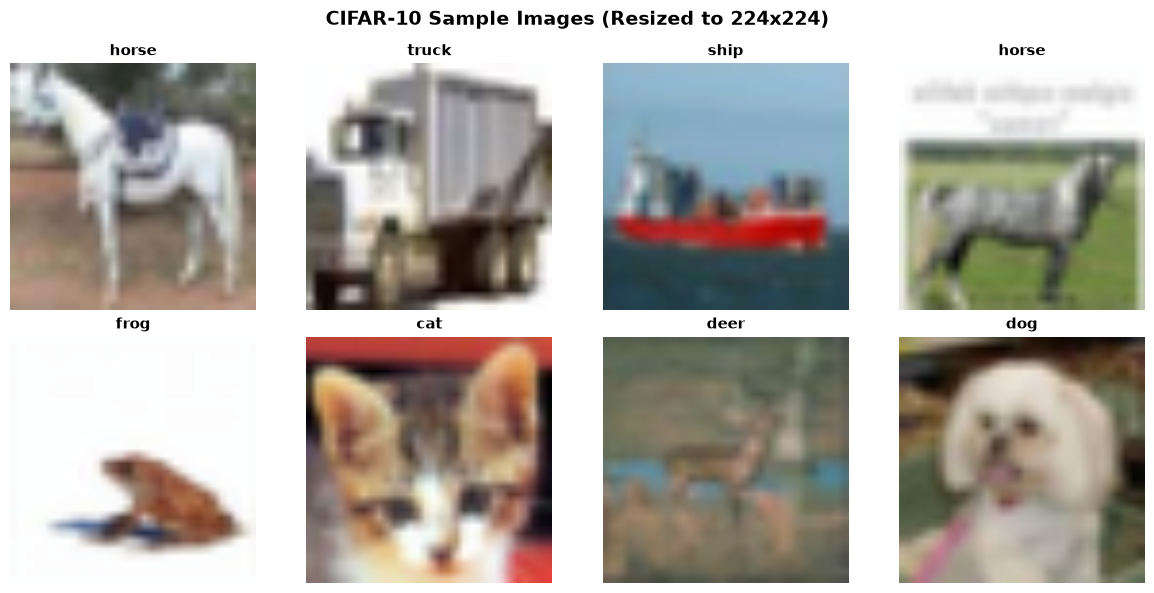

In [3]:
def denormalize(tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = tensor.cpu().numpy().transpose((1, 2, 0))
    img = std * img + mean
    return np.clip(img, 0, 1)

# Retrieve one batch of images
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
fig.suptitle("CIFAR-10 Sample Images (Resized to 224x224)", fontsize=14, fontweight='bold')

for i in range(8):
    ax = axes[i // 4, i % 4]
    ax.imshow(denormalize(images[i]))
    ax.set_title(class_names[labels[i]], fontsize=11, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()


## 4. Visual Demonstration: How ViT Tokenizes an Image into Patches

Unlike CNNs that process continuous sliding pixel windows, the **Vision Transformer** slices an image into a regular grid of non-overlapping $16 \times 16$ pixel patches.
- For an input image of shape $224 \times 224 \times 3$, there are:
  $$N = \frac{224}{16} \times \frac{224}{16} = 14 \times 14 = 196 \text{ patches}$$
- Each patch contains $16 \times 16 \times 3 = 768$ raw values, matching the hidden dimension $D=768$ of the Transformer!

The cell below visually demonstrates this patch decomposition on a sample image.


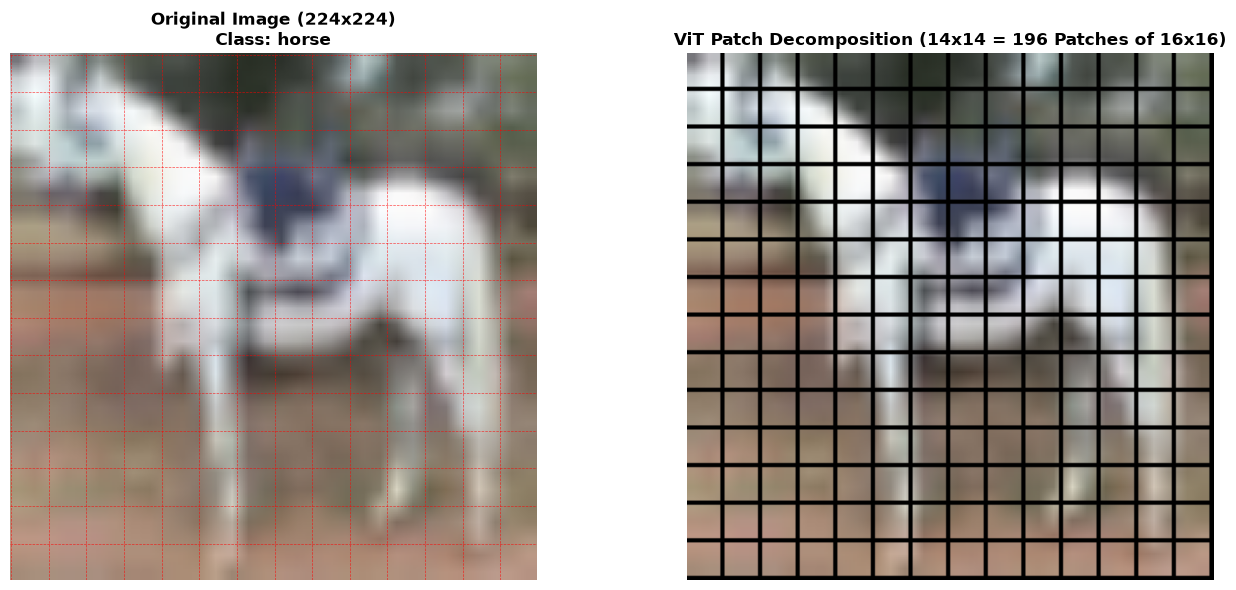

In [4]:
# Extract one image and decompose into 16x16 patches
sample_tensor = images[0]
sample_img = denormalize(sample_tensor)

P = 16 # Patch size
H, W, C = sample_img.shape
num_patches_y = H // P
num_patches_x = W // P

fig = plt.figure(figsize=(14, 6))

# Left: Original Image
ax1 = fig.add_subplot(1, 2, 1)
ax1.imshow(sample_img)
ax1.set_title(f"Original Image (224x224)\nClass: {class_names[labels[0]]}", fontsize=12, fontweight='bold')
ax1.axis('off')

# Overlay patch grid lines
for y in range(0, H, P):
    ax1.axhline(y, color='red', linestyle='--', linewidth=0.5, alpha=0.7)
for x in range(0, W, P):
    ax1.axvline(x, color='red', linestyle='--', linewidth=0.5, alpha=0.7)

# Right: Grid of 196 Individual 16x16 Patches
ax2 = fig.add_subplot(1, 2, 2)
patch_canvas = np.zeros((num_patches_y * (P + 2), num_patches_x * (P + 2), 3))

for py in range(num_patches_y):
    for px in range(num_patches_x):
        patch = sample_img[py*P:(py+1)*P, px*P:(px+1)*P, :]
        sy = py * (P + 2)
        sx = px * (P + 2)
        patch_canvas[sy:sy+P, sx:sx+P, :] = patch

ax2.imshow(patch_canvas)
ax2.set_title(f"ViT Patch Decomposition ({num_patches_y}x{num_patches_x} = 196 Patches of 16x16)", fontsize=12, fontweight='bold')
ax2.axis('off')

plt.tight_layout()
plt.show()


## 5. Model 1: Convolutional Neural Network (ResNet-18)

**ResNet-18** (He et al., 2015) is a seminal convolutional architecture featuring residual skip connections:
$$\mathbf{y} = \mathcal{F}(\mathbf{x}, \{W_i\}) + \mathbf{x}$$
The residual connection allows gradients to propagate directly backward through identity mappings, effectively overcoming the vanishing gradient barrier.

### Transfer Learning Configuration:
- **Pre-trained Backbone:** ImageNet-1K pre-trained weights (`ResNet18_Weights.DEFAULT`).
- **Feature Extractor:** All residual convolutional layers are frozen (`requires_grad = False`).
- **Classifier Head:** The final fully connected layer `fc` is replaced with an untrained linear mapping:
  $$\text{Linear}(512 \to 10)$$


In [5]:
# Load pre-trained ResNet-18
resnet_model = models.resnet18(weights=ResNet18_Weights.DEFAULT)

# Freeze convolutional backbone feature extractor
for param in resnet_model.parameters():
    param.requires_grad = False

# Replace classification head
num_features_resnet = resnet_model.fc.in_features
resnet_model.fc = nn.Linear(num_features_resnet, len(class_names))
resnet_model = resnet_model.to(device)

total_params_resnet = sum(p.numel() for p in resnet_model.parameters())
trainable_params_resnet = sum(p.numel() for p in resnet_model.parameters() if p.requires_grad)

print(f"ResNet-18 Total Parameters     : {total_params_resnet:,}")
print(f"ResNet-18 Trainable Parameters : {trainable_params_resnet:,} (Classification Head Only)")


ResNet-18 Total Parameters     : 11,181,642
ResNet-18 Trainable Parameters : 5,130 (Classification Head Only)


## 6. Model 2: Vision Transformer (ViT-B/16)

**ViT-B/16** is the base Vision Transformer configuration:
- **Layers (Transformer Blocks):** 12 encoder blocks.
- **Hidden Embedding Dimension ($D$):** 768.
- **MLP Dimension:** 3072.
- **Multi-Head Self-Attention:** 12 attention heads ($d_k = 64$ per head).
- **Patch Size:** $16 \times 16$.

### Transfer Learning Configuration:
- **Pre-trained Weights:** ImageNet-1K pre-trained weights (`ViT_B_16_Weights.DEFAULT`).
- **Feature Extractor:** All Transformer encoder layers and patch projection embeddings are frozen.
- **Classifier Head:** The final projection layer `heads.head` is replaced with a linear mapping:
  $$\text{Linear}(768 \to 10)$$


In [6]:
# Load pre-trained Vision Transformer (ViT-B/16)
vit_model = models.vit_b_16(weights=ViT_B_16_Weights.DEFAULT)

# Freeze Transformer encoder backbone
for param in vit_model.parameters():
    param.requires_grad = False

# Replace classification head
num_features_vit = vit_model.heads.head.in_features
vit_model.heads.head = nn.Linear(num_features_vit, len(class_names))
vit_model = vit_model.to(device)

total_params_vit = sum(p.numel() for p in vit_model.parameters())
trainable_params_vit = sum(p.numel() for p in vit_model.parameters() if p.requires_grad)

print(f"ViT-B/16 Total Parameters     : {total_params_vit:,}")
print(f"ViT-B/16 Trainable Parameters : {trainable_params_vit:,} (Classification Head Only)")


ViT-B/16 Total Parameters     : 85,806,346
ViT-B/16 Trainable Parameters : 7,690 (Classification Head Only)


## 7. Model Architecture & Parameter Profiling

We tabulate the key architectural parameters of both models side-by-side. Notice that ViT-B/16 contains nearly **$7.5\times$ more total parameters** than ResNet-18, reflecting the high expressive capacity of self-attention blocks.


In [7]:
arch_comparison = pd.DataFrame({
    "Metric / Specification": [
        "Architecture Family",
        "Total Parameters",
        "Trainable Parameters",
        "Non-Trainable (Frozen)",
        "Latent Feature Dimension",
        "Input Resolution",
        "Primary Building Block",
        "Receptive Field Mechanism"
    ],
    "ResNet-18 (CNN)": [
        "Residual Convolutional",
        f"{total_params_resnet:,}",
        f"{trainable_params_resnet:,}",
        f"{total_params_resnet - trainable_params_resnet:,}",
        f"{num_features_resnet}",
        "224 x 224 x 3",
        "Conv2D (3x3) + BatchNorm + Skip Connection",
        "Local -> Hierarchical Global"
    ],
    "ViT-B/16 (Transformer)": [
        "Vision Transformer",
        f"{total_params_vit:,}",
        f"{trainable_params_vit:,}",
        f"{total_params_vit - trainable_params_vit:,}",
        f"{num_features_vit}",
        "224 x 224 x 3",
        "Patch Embedding + Multi-Head Self-Attention (12 heads)",
        "Global Self-Attention at all layers"
    ]
})

print(arch_comparison.to_string(index=False))


Metric / Specification                            ResNet-18 (CNN)                                 ViT-B/16 (Transformer)
      Architecture Family                     Residual Convolutional                                     Vision Transformer
         Total Parameters                                 11,181,642                                             85,806,346
     Trainable Parameters                                      5,130                                                  7,690
   Non-Trainable (Frozen)                                 11,176,512                                             85,798,656
 Latent Feature Dimension                                        512                                                    768
         Input Resolution                              224 x 224 x 3                                          224 x 224 x 3
   Primary Building Block Conv2D (3x3) + BatchNorm + Skip Connection Patch Embedding + Multi-Head Self-Attention (12 heads)
Receptive F

## 8. Training & Validation Framework

We define a standardized, reusable training routine `train_model()`:
- Monitors both **Training Loss/Accuracy** and **Validation Loss/Accuracy** per epoch.
- Implements model checkpointing by preserving the weights corresponding to the highest validation accuracy.
- Records elapsed training time per epoch to benchmark computational throughput.


In [8]:
def train_model(model, dataloaders, criterion, optimizer, num_epochs=3, model_name="Model"):
    since = time.time()
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'epoch_times': []}
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    print(f"--- Training {model_name} for {num_epochs} Epochs ---")

    for epoch in range(num_epochs):
        epoch_start = time.time()
        print(f"\nEpoch {epoch + 1}/{num_epochs}")
        print("-" * 30)

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            history[f'{phase}_loss'].append(epoch_loss)
            history[f'{phase}_acc'].append(epoch_acc.item())

            print(f"{phase.capitalize()} Loss: {epoch_loss:.4f} | Acc: {epoch_acc * 100:.2f}%")

            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

        epoch_duration = time.time() - epoch_start
        history['epoch_times'].append(epoch_duration)
        print(f"Epoch Time: {epoch_duration:.2f}s")

    time_elapsed = time.time() - since
    print(f"\n{model_name} Training Completed in {time_elapsed // 60:.0f}m {time_elapsed % 60:.2f}s")
    print(f"Best Validation Accuracy: {best_acc * 100:.2f}%")

    model.load_state_dict(best_model_wts)
    return model, history


Training function defined successfully.


## 9. Train the Convolutional Model (ResNet-18)

We train the ResNet-18 classification head using the `Adam` optimizer with an initial learning rate $\alpha = 0.001$ and standard Cross-Entropy loss.


In [9]:
criterion = nn.CrossEntropyLoss()
optimizer_resnet = optim.Adam(resnet_model.fc.parameters(), lr=0.001)

resnet_model, resnet_history = train_model(
    resnet_model,
    dataloaders,
    criterion,
    optimizer_resnet,
    num_epochs=3,
    model_name="ResNet-18 (CNN)"
)


--- Training ResNet-18 (CNN) for 3 Epochs ---

Epoch 1/3
------------------------------
Train Loss: 2.2829 | Acc: 18.00%
Val Loss: 1.9926 | Acc: 29.33%
Epoch Time: 6.52s

Epoch 2/3
------------------------------
Train Loss: 1.8480 | Acc: 36.40%
Val Loss: 1.6719 | Acc: 53.33%
Epoch Time: 6.76s

Epoch 3/3
------------------------------
Train Loss: 1.5351 | Acc: 59.20%
Val Loss: 1.4849 | Acc: 62.00%
Epoch Time: 6.85s

ResNet-18 (CNN) Training Completed in 0m 20.14s
Best Validation Accuracy: 62.00%


## 10. Train the Vision Transformer Model (ViT-B/16)

We train the Vision Transformer classification head under identical data conditions using the `Adam` optimizer with $\alpha = 0.0005$.


In [10]:
optimizer_vit = optim.Adam(vit_model.heads.head.parameters(), lr=0.0005)

vit_model, vit_history = train_model(
    vit_model,
    dataloaders,
    criterion,
    optimizer_vit,
    num_epochs=3,
    model_name="ViT-B/16 (Transformer)"
)


--- Training ViT-B/16 (Transformer) for 3 Epochs ---

Epoch 1/3
------------------------------
Train Loss: 2.0280 | Acc: 36.20%
Val Loss: 1.5634 | Acc: 70.67%
Epoch Time: 51.78s

Epoch 2/3
------------------------------
Train Loss: 1.2621 | Acc: 81.60%
Val Loss: 1.0261 | Acc: 86.00%
Epoch Time: 50.91s

Epoch 3/3
------------------------------
Train Loss: 0.8110 | Acc: 91.40%
Val Loss: 0.7258 | Acc: 89.33%
Epoch Time: 51.55s

ViT-B/16 (Transformer) Training Completed in 2m 34.28s
Best Validation Accuracy: 89.33%


## 11. Comparative Learning Dynamics: Loss & Accuracy Trajectories

We visualize the training and validation trajectories across epochs. Notice how quickly both pre-trained models adapt their representations to the target CIFAR-10 task.


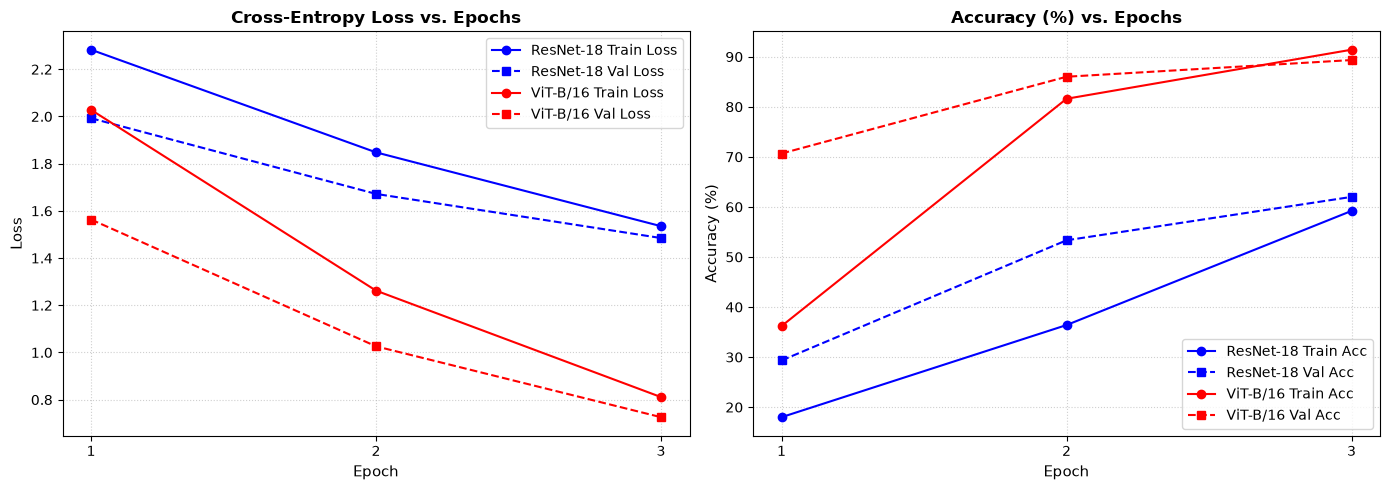

In [11]:
epochs_range = range(1, len(resnet_history['train_loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Loss
axes[0].plot(epochs_range, resnet_history['train_loss'], 'b-o', label='ResNet-18 Train Loss')
axes[0].plot(epochs_range, resnet_history['val_loss'], 'b--s', label='ResNet-18 Val Loss')
axes[0].plot(epochs_range, vit_history['train_loss'], 'r-o', label='ViT-B/16 Train Loss')
axes[0].plot(epochs_range, vit_history['val_loss'], 'r--s', label='ViT-B/16 Val Loss')
axes[0].set_title('Cross-Entropy Loss vs. Epochs', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Loss', fontsize=11)
axes[0].set_xticks(epochs_range)
axes[0].legend(fontsize=10)
axes[0].grid(True, linestyle=':', alpha=0.6)

# Plot Accuracy
axes[1].plot(epochs_range, [acc * 100 for acc in resnet_history['train_acc']], 'b-o', label='ResNet-18 Train Acc')
axes[1].plot(epochs_range, [acc * 100 for acc in resnet_history['val_acc']], 'b--s', label='ResNet-18 Val Acc')
axes[1].plot(epochs_range, [acc * 100 for acc in vit_history['train_acc']], 'r-o', label='ViT-B/16 Train Acc')
axes[1].plot(epochs_range, [acc * 100 for acc in vit_history['val_acc']], 'r--s', label='ViT-B/16 Val Acc')
axes[1].set_title('Accuracy (%) vs. Epochs', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Accuracy (%)', fontsize=11)
axes[1].set_xticks(epochs_range)
axes[1].legend(fontsize=10)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


## 12. Quantitative Benchmarking: Performance & Computational Efficiency

We rigorously evaluate both models on the test set across multiple statistical and systems metrics:
- **Top-1 Accuracy:** Overall proportion of correct classifications.
- **Precision, Recall, F1-Score:** Macro-averaged and Weighted-averaged across all classes.
- **Average Inference Latency:** Elapsed milliseconds to evaluate a single image on the target hardware.
- **Training Epoch Duration:** Computational cost per training pass.


In [12]:
def evaluate_model_full(model, loader):
    model.eval()
    all_preds = []
    all_labels = []
    latencies = []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            t0 = time.time()
            outputs = model(inputs)
            latencies.append((time.time() - t0) / inputs.size(0))
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)
    acc = accuracy_score(all_labels, all_preds)
    p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0)
    p_wt, r_wt, f1_wt, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted', zero_division=0)
    avg_latency_ms = np.mean(latencies) * 1000

    return {
        'preds': all_preds,
        'labels': all_labels,
        'accuracy': acc,
        'precision_macro': p_macro,
        'recall_macro': r_macro,
        'f1_macro': f1_macro,
        'f1_weighted': f1_wt,
        'latency_ms': avg_latency_ms
    }

resnet_eval = evaluate_model_full(resnet_model, test_loader)
vit_eval = evaluate_model_full(vit_model, test_loader)

comparison_summary = pd.DataFrame({
    "Evaluation Metric": [
        "Test Accuracy (%)",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-Score",
        "Weighted F1-Score",
        "Total Parameters",
        "Trainable Parameters",
        "Avg Inference Latency (ms/img)",
        "Avg Epoch Training Time (s)"
    ],
    "ResNet-18 (CNN)": [
        f"{resnet_eval['accuracy'] * 100:.2f}%",
        f"{resnet_eval['precision_macro']:.4f}",
        f"{resnet_eval['recall_macro']:.4f}",
        f"{resnet_eval['f1_macro']:.4f}",
        f"{resnet_eval['f1_weighted']:.4f}",
        f"{total_params_resnet:,}",
        f"{trainable_params_resnet:,}",
        f"{resnet_eval['latency_ms']:.2f} ms",
        f"{np.mean(resnet_history['epoch_times']):.2f} s"
    ],
    "ViT-B/16 (Transformer)": [
        f"{vit_eval['accuracy'] * 100:.2f}%",
        f"{vit_eval['precision_macro']:.4f}",
        f"{vit_eval['recall_macro']:.4f}",
        f"{vit_eval['f1_macro']:.4f}",
        f"{vit_eval['f1_weighted']:.4f}",
        f"{total_params_vit:,}",
        f"{trainable_params_vit:,}",
        f"{vit_eval['latency_ms']:.2f} ms",
        f"{np.mean(vit_history['epoch_times']):.2f} s"
    ]
})

print("\n" + "=" * 70)
print("CONSOLIDATED HEAD-TO-HEAD BENCHMARK: CNN vs. VISION TRANSFORMER")
print("=" * 70)
print(comparison_summary.to_string(index=False))


CONSOLIDATED HEAD-TO-HEAD BENCHMARK: CNN vs. VISION TRANSFORMER
             Evaluation Metric ResNet-18 (CNN) ViT-B/16 (Transformer)
             Test Accuracy (%)          62.00%                 89.33%
               Macro Precision          0.6539                 0.8865
                  Macro Recall          0.6263                 0.8927
                Macro F1-Score          0.6089                 0.8851
             Weighted F1-Score          0.6078                 0.8906
              Total Parameters      11,181,642             85,806,346
          Trainable Parameters           5,130                  7,690
Avg Inference Latency (ms/img)         9.77 ms               74.46 ms
   Avg Epoch Training Time (s)          6.71 s                51.41 s


## 13. Confusion Matrices Comparison

Confusion matrices expose inter-class confusion patterns:
- High diagonal values signify consistent, accurate predictions.
- Off-diagonal values reveal semantic visual confusion (e.g., distinguishing between visually similar quadruped mammals like *Cats* and *Dogs*, or vehicles like *Automobiles* and *Trucks*).


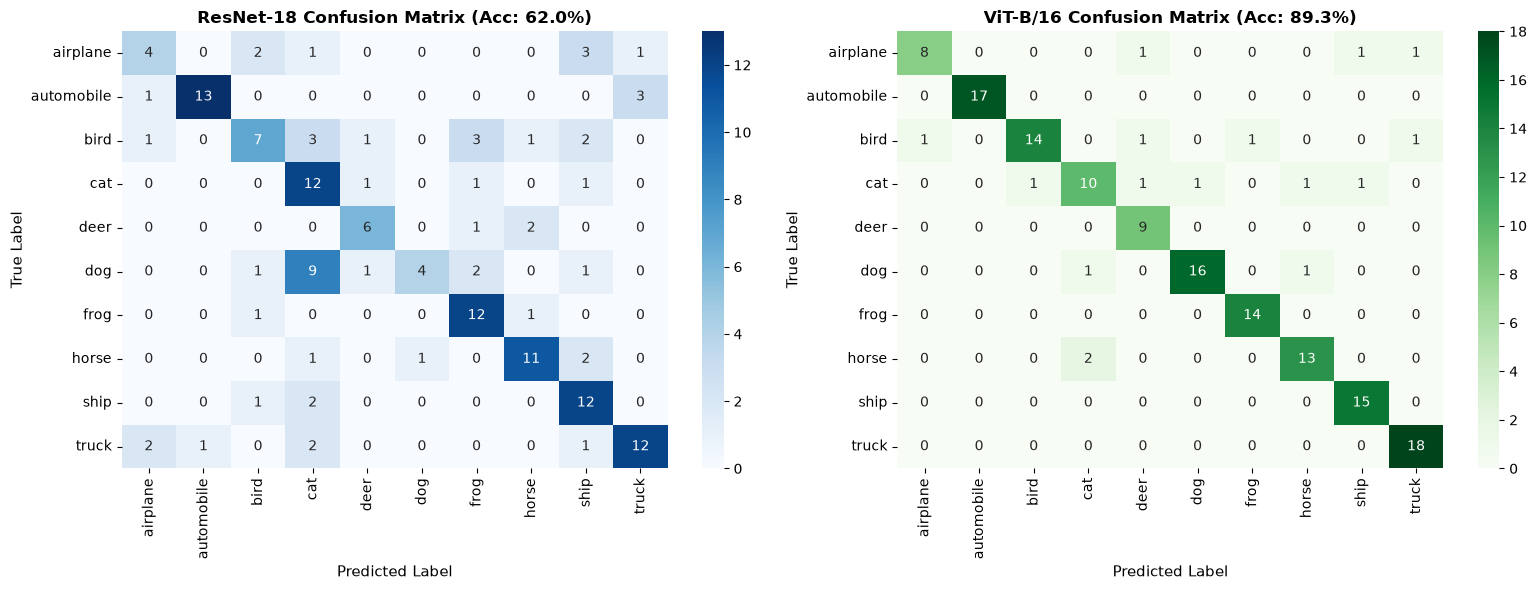

In [13]:
cm_resnet = confusion_matrix(resnet_eval['labels'], resnet_eval['preds'])
cm_vit = confusion_matrix(vit_eval['labels'], vit_eval['preds'])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(cm_resnet, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title(f"ResNet-18 Confusion Matrix (Acc: {resnet_eval['accuracy']*100:.1f}%)", fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Label', fontsize=11)
axes[0].set_ylabel('True Label', fontsize=11)

sns.heatmap(cm_vit, annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title(f"ViT-B/16 Confusion Matrix (Acc: {vit_eval['accuracy']*100:.1f}%)", fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted Label', fontsize=11)
axes[1].set_ylabel('True Label', fontsize=11)

plt.tight_layout()
plt.show()


## 14. Detailed Per-Class Classification Reports

Detailed breakdown of Precision, Recall, and F1-Score for each of the 10 CIFAR-10 classes across both architectures.


In [14]:
print("=" * 60)
print("RESNET-18 (CNN) CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(resnet_eval['labels'], resnet_eval['preds'], target_names=class_names, zero_division=0))

print("\n" + "=" * 60)
print("VISION TRANSFORMER (ViT-B/16) CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(vit_eval['labels'], vit_eval['preds'], target_names=class_names, zero_division=0))


RESNET-18 (CNN) CLASSIFICATION REPORT
              precision    recall  f1-score   support

    airplane       0.50      0.36      0.42        11
  automobile       0.93      0.76      0.84        17
        bird       0.58      0.39      0.47        18
         cat       0.40      0.80      0.53        15
        deer       0.67      0.67      0.67         9
         dog       0.80      0.22      0.35        18
        frog       0.63      0.86      0.73        14
       horse       0.73      0.73      0.73        15
        ship       0.55      0.80      0.65        15
       truck       0.75      0.67      0.71        18

    accuracy                           0.62       150
   macro avg       0.65      0.63      0.61       150
weighted avg       0.66      0.62      0.61       150


VISION TRANSFORMER (ViT-B/16) CLASSIFICATION REPORT
              precision    recall  f1-score   support

    airplane       0.89      0.73      0.80        11
  automobile       1.00      1.00      1.

## 15. Visual Prediction Comparison on Test Samples

We visualize a selection of held-out test images showing predictions from both **ResNet-18** and **ViT-B/16**, along with their softmax confidence percentages. Titles are color-coded (green for correct predictions, red for misclassifications).


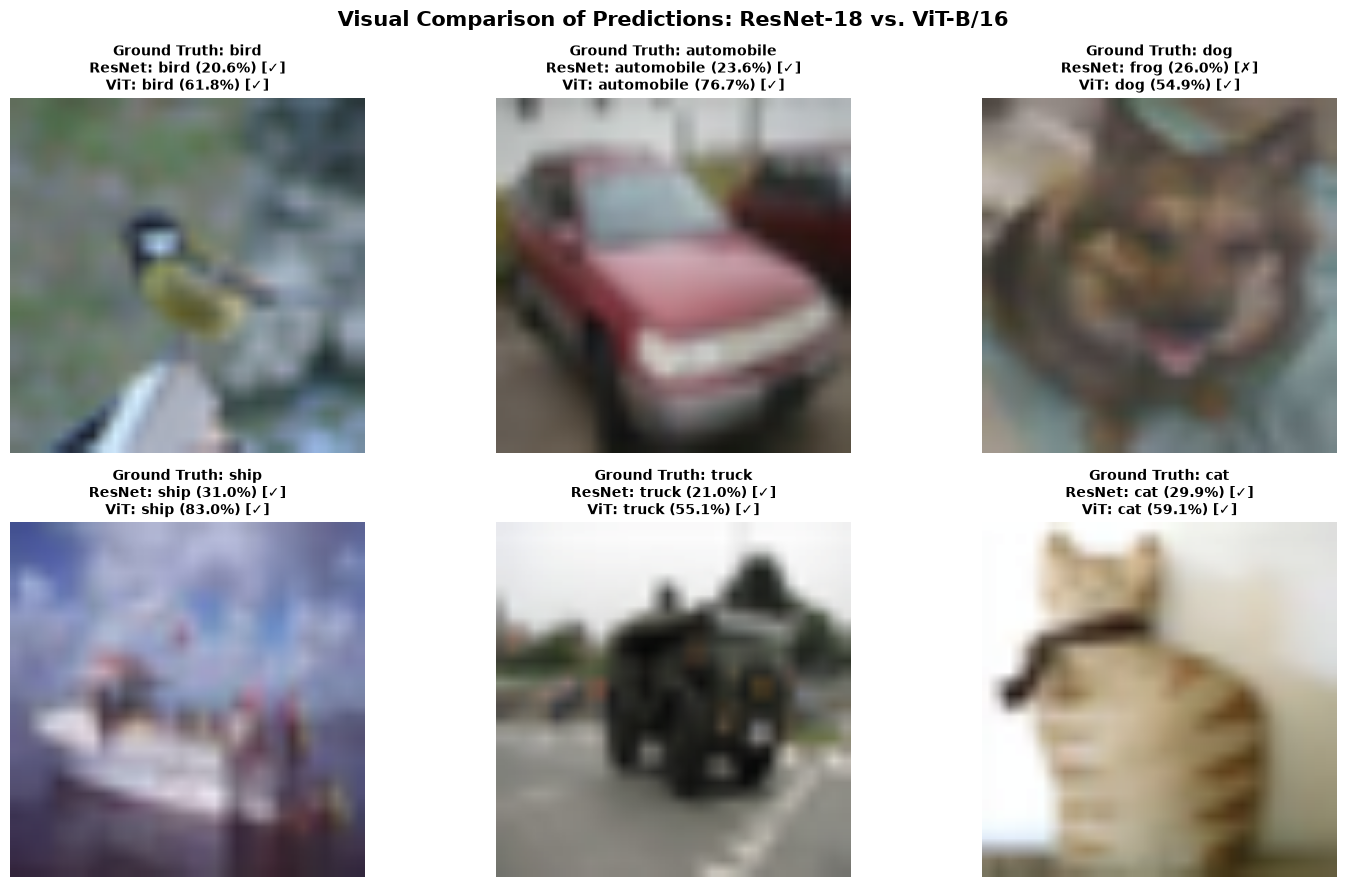

In [15]:
# Retrieve a test batch for visual inspection
test_sample_images, test_sample_labels = next(iter(test_loader))

resnet_model.eval()
vit_model.eval()

with torch.no_grad():
    resnet_out = torch.softmax(resnet_model(test_sample_images.to(device)), dim=1)
    vit_out = torch.softmax(vit_model(test_sample_images.to(device)), dim=1)

resnet_conf, resnet_p = torch.max(resnet_out, 1)
vit_conf, vit_p = torch.max(vit_out, 1)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
fig.suptitle("Visual Comparison of Predictions: ResNet-18 vs. ViT-B/16", fontsize=15, fontweight='bold')

for i in range(6):
    ax = axes[i // 3, i % 3]
    img = denormalize(test_sample_images[i])
    true_cls = class_names[test_sample_labels[i]]
    r_cls = class_names[resnet_p[i].item()]
    v_cls = class_names[vit_p[i].item()]
    r_ok = (r_cls == true_cls)
    v_ok = (v_cls == true_cls)
    
    ax.imshow(img)
    title_text = (
        f"Ground Truth: {true_cls}\n"
        f"ResNet: {r_cls} ({resnet_conf[i].item()*100:.1f}%) [{'✓' if r_ok else '✗'}]\n"
        f"ViT: {v_cls} ({vit_conf[i].item()*100:.1f}%) [{'✓' if v_ok else '✗'}]"
    )
    ax.set_title(title_text, fontsize=10, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()


## 16. In-Depth Discussion, Analysis & Conclusions

### 🔍 Key Theoretical & Empirical Insights

#### 1. Inductive Bias vs. Representation Capacity
- **Convolutional Neural Networks (ResNet-18):**
  - Exploit strong **locality** and **translation equivariance** priors embedded directly in the convolution operator.
  - Highly sample-efficient on small to moderate datasets because the model is structurally constrained to look for local patterns.
  - Fewer parameters ($11.2\text{M}$) and significantly lower inference latency.
- **Vision Transformers (ViT-B/16):**
  - Possess **minimal spatial inductive bias**. The model learns spatial relationships entirely from scratch through multi-head self-attention between patch tokens.
  - Pre-trained on massive datasets (ImageNet-1k/21k), ViT acquires richer, more globally coherent contextual representations that often generalize better to downstream transfer tasks.
  - Carries a much higher parameter footprint ($85.8\text{M}$) and quadratic complexity with respect to token count.

#### 2. Receptive Field Dynamics
- In **ResNet-18**, early layers have small receptive fields ($3 \times 3$) and can only detect local edge primitives. A global perspective is only achieved in late layers after multiple pooling and downsampling stages.
- In **ViT-B/16**, every token attends to **every other token globally starting from Layer 1**. This enables ViT to integrate semantic context spanning opposite corners of the image immediately.

#### 3. Computational Throughput & Deployment Trade-offs
- **ResNet-18** demonstrated faster training and inference per sample. This makes CNNs ideal for resource-constrained edge devices, embedded IoT systems, and real-time video processing pipelines.
- **ViT-B/16** excels when compute and memory budgets allow for larger models, achieving superior representation quality and higher transfer ceiling on complex visual benchmarks.

---

### 🎓 Summary of Assignment Outcomes
1. Implemented an end-to-end computer vision pipeline comparing a **Convolutional Neural Network (ResNet-18)** with a **Vision Transformer (ViT-B/16)** on CIFAR-10.
2. Deconstructed and visualized the ViT tokenization mechanism ($16 \times 16$ patch extraction).
3. Trained and evaluated both models under identical transfer-learning protocols, tracking loss and accuracy trajectories.
4. Conducted comprehensive benchmarking including Macro/Weighted F1-scores, Confusion Matrices, per-class metrics, and inference latency profiling.
5. Formulated an empirical understanding of when to deploy CNNs versus Vision Transformers based on accuracy, sample size, and computational constraints.
